<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">PageRank sensible a tópico en la red de citas cit-HepPh</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Tópicos definidos como comunidades del grafo, PageRank con teletransportación a cada tópico y consultas como mezcla de tópicos.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

El PageRank general del notebook 2 da una sola medida de importancia para todos. El **PageRank sensible a tópico**
(Haveliwala, 2002; Leskovec, Rajaraman y Ullman, cap. 5) calcula un vector por tópico: el lector aleatorio, cuando se
teletransporta, salta solo a artículos de ese tópico. Así, un artículo es importante **para un tema**. Una consulta de
un usuario interesado en varios temas se responde combinando los vectores precalculados.

El conjunto de datos no trae tópicos, así que se definen a partir del propio grafo, como **comunidades de Louvain**
sobre el grafo de citas no dirigido. No se usan títulos ni resúmenes, así que los tópicos **no tienen nombre**: se
describen por su tamaño, su distribución por año y sus artículos más citados.

### Los datos

Se usan las salidas de los notebooks anteriores, en `data/processed/`:

- `adyacencia.npz`: la matriz de adyacencia CSR del notebook 2 y su arreglo de IDs. Primero se verifica que coincida
  con `nodos_limpios.parquet`.
- `aristas_limpias.parquet` y `nodos_limpios.parquet`, del notebook 1.

Como se decidió en el notebook 2 (sección 3.1), el análisis usa el grafo **sin citas al futuro** (`es_futuro`).

### Contenido

1. **Datos y verificación** de la matriz contra `nodos_limpios.parquet`.
2. **Tópicos con Louvain:** número de comunidades, tamaños, umbral y cobertura; descripción de cada tópico.
3. **PageRank sensible a tópico:** un vector por tópico y comparación entre tópicos y con el PageRank general.
4. **Consulta de usuario** como mezcla de tópicos.
5. **Conclusiones y limitaciones** de la práctica (los tres notebooks).

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

RUTA_PROCESADOS = Path("..") / "data" / "processed"
ARCHIVO_MATRIZ = RUTA_PROCESADOS / "adyacencia.npz"
SEMILLA = 42
BETA = 0.85
TOL = 1e-10

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
# Escala secuencial de un solo tono (azules) para conteos, proporciones y similitudes; vacío = blanco
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"


def jaccard_top(a, b, k):
    """
    Índice de Jaccard entre los k nodos con mayor puntaje de dos rankings.

    Parámetros
    ----------
    a, b : pd.Series
        Puntajes por índice de nodo.
    k : int
        Tamaño del top.

    Retorna
    -------
    float
        |top_a ∩ top_b| / |top_a ∪ top_b|.
    """
    ta, tb = set(a.nlargest(k).index), set(b.nlargest(k).index)
    return len(ta & tb) / len(ta | tb)


def pagerank(grafo, beta=BETA, **kwargs):
    """
    Calcula PageRank con networkx y lo devuelve como Serie ordenada por índice de nodo.

    Parámetros
    ----------
    grafo : nx.DiGraph
        Grafo con nodos 0..n-1.
    beta : float
        Probabilidad de seguir un enlace (`alpha` en networkx).
    **kwargs
        Argumentos adicionales para `nx.pagerank` (por ejemplo, `personalization`).

    Retorna
    -------
    pd.Series
        Puntaje de cada nodo; suma 1.
    """
    return pd.Series(nx.pagerank(grafo, alpha=beta, tol=TOL, max_iter=1000, **kwargs)).sort_index()

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Datos y verificación</span></div>


La matriz de adyacencia se lee del archivo que guardó el notebook 2. Antes de usarla se comprueba que corresponda a
`nodos_limpios.parquet`:

- los mismos IDs, sin repetidos;
- los grados por fila y por columna iguales a `k_out` y `k_in`;
- el orden cronológico de los índices.

Después se quitan las citas al futuro con la marca `es_futuro` de `aristas_limpias.parquet`.

In [2]:
# Carga de la matriz y su mapeo, y verificación contra nodos_limpios.parquet
A = sp.load_npz(ARCHIVO_MATRIZ)
ids = np.load(ARCHIVO_MATRIZ)["ids"].astype(str)
nodos_pq = pd.read_parquet(RUTA_PROCESADOS / "nodos_limpios.parquet")
aristas = pd.read_parquet(RUTA_PROCESADOS / "aristas_limpias.parquet")
n = A.shape[0]

nodos = nodos_pq.set_index("id").loc[ids].reset_index()
nodos.index.name = "indice"
verificacion = pd.Series({
    "Dimensión de A = número de nodos": A.shape == (len(nodos_pq), len(nodos_pq)),
    "IDs únicos en el .npz": pd.Index(ids).is_unique,
    "Mismos IDs que nodos_limpios.parquet": set(ids) == set(nodos_pq["id"]),
    "Grado de salida de A = k_out": np.array_equal(np.asarray(A.sum(axis=1)).ravel(), nodos["k_out"].to_numpy()),
    "Grado de entrada de A = k_in": np.array_equal(np.asarray(A.sum(axis=0)).ravel(), nodos["k_in"].to_numpy()),
    "Aristas de A = filas de aristas_limpias": A.nnz == len(aristas),
    "Índices en orden cronológico (mes_id)": nodos["mes_id"].is_monotonic_increasing,
}, name="Correcto").rename_axis("Comprobación").to_frame()
display(verificacion)
assert verificacion["Correcto"].all()

# Grafo de análisis: sin las citas al futuro
indice_de = pd.Series(nodos.index.to_numpy(), index=nodos["id"])
filas = indice_de.loc[aristas["origen"]].to_numpy()
columnas = indice_de.loc[aristas["destino"]].to_numpy()
pasado = ~aristas["es_futuro"].to_numpy()
A_sf = sp.csr_matrix((np.ones(pasado.sum()), (filas[pasado], columnas[pasado])), shape=(n, n))
G_sf = nx.from_scipy_sparse_array(A_sf, create_using=nx.DiGraph)
nodos["k_in"] = np.asarray(A_sf.sum(axis=0)).ravel().astype(int)
nodos["k_out"] = np.asarray(A_sf.sum(axis=1)).ravel().astype(int)
print(f"Grafo de análisis: {G_sf.number_of_nodes():,} nodos y {G_sf.number_of_edges():,} aristas "
      f"(se quitan {(~pasado).sum():,} citas al futuro)")

,Correcto
Comprobación,
Dimensión de A = número de nodos,True
IDs únicos en el .npz,True
Mismos IDs que nodos_limpios.parquet,True
Grado de salida de A = k_out,True
Grado de entrada de A = k_in,True
Aristas de A = filas de aristas_limpias,True
Índices en orden cronológico (mes_id),True


Grafo de análisis: 34,546 nodos y 419,682 aristas (se quitan 1,852 citas al futuro)


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TÓPICOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Tópicos con Louvain</span></div>


**Método.** Louvain (Blondel *et al.*, 2008) busca una partición de los nodos que maximice la **modularidad**:

$$Q = \frac{1}{2m}\sum_{ij}\left(A_{ij} - \gamma\,\frac{k_i k_j}{2m}\right)\delta(c_i, c_j),$$

es decir, la fracción de aristas dentro de las comunidades menos la que se esperaría al azar con los mismos grados.
$\gamma$ es la **resolución**: valores mayores dan comunidades más pequeñas. Se usa sobre el grafo **no dirigido**,
porque dos artículos del mismo tema están relacionados citen en la dirección que citen, con `resolution=1` (la
modularidad estándar) y `seed=42`, porque el orden en que Louvain recorre los nodos es aleatorio.

**De comunidades a tópicos.** Las comunidades muy pequeñas no sirven como tópico: un conjunto de teletransportación de
unos cuantos nodos concentra todo el puntaje en ellos. Se toman como tópicos las comunidades con al menos el **1 %** de
los nodos. Los nodos de las comunidades pequeñas **no están en ningún conjunto $S$**, pero siguen en el grafo y
**pueden recibir puntaje**: lo reciben en un vector si se puede llegar a ellos siguiendo citas desde su $S$ (la
sección 3 cuenta cuántos).

,Valor
"Louvain (resolution = 1, seed = 42)",
Tiempo de Louvain,31.3 s
Comunidades,103
Modularidad Q,0.7281
Comunidad más grande / más pequeña,"4,295 / 1 nodos"
Umbral de tópico (≥ 1 % de los nodos),≥ 345 nodos
Tópicos (comunidades sobre el umbral),15
Cobertura de los tópicos,"34,020 nodos (98.48 %)"
Comunidades pequeñas,"88 (526 nodos, 1.52 %)"
· de un solo nodo,16


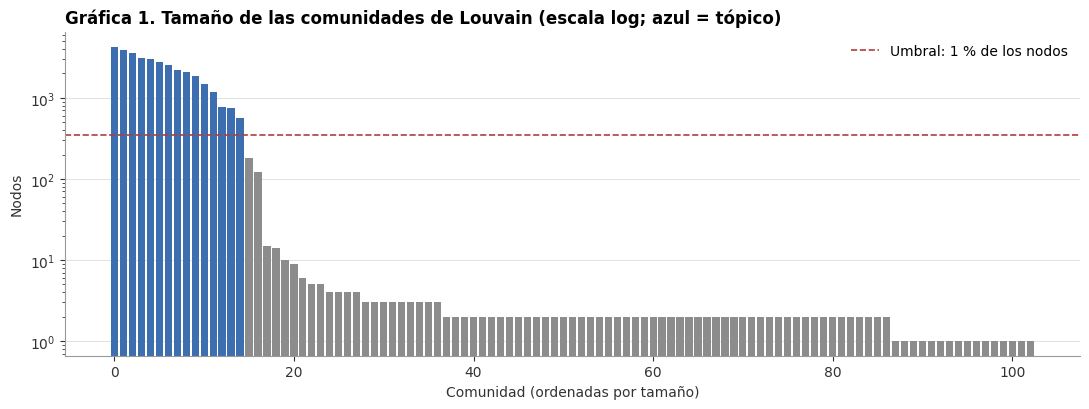

In [3]:
# Louvain sobre el grafo no dirigido, con semilla y resolución fijas
U = G_sf.to_undirected()
t0 = time.perf_counter()
comunidades = nx.community.louvain_communities(U, seed=SEMILLA, resolution=1)
segundos_louvain = time.perf_counter() - t0
comunidades = sorted(comunidades, key=len, reverse=True)
modularidad = nx.community.modularity(U, comunidades)

nodos["comunidad"] = -1
for c, miembros in enumerate(comunidades):
    nodos.loc[list(miembros), "comunidad"] = c
tamanos = pd.Series([len(c) for c in comunidades], name="nodos")

UMBRAL = 0.01
es_topico = tamanos >= UMBRAL * n
TOPICOS = list(tamanos[es_topico].index)
nodos["topico"] = nodos["comunidad"].where(nodos["comunidad"].isin(TOPICOS), -1)

resumen_louvain = pd.Series({
    "Tiempo de Louvain": f"{segundos_louvain:.1f} s",
    "Comunidades": f"{len(comunidades):,}",
    "Modularidad Q": f"{modularidad:.4f}",
    "Comunidad más grande / más pequeña": f"{tamanos.max():,} / {tamanos.min():,} nodos",
    f"Umbral de tópico (≥ {pct(UMBRAL, 0)} de los nodos)": f"≥ {UMBRAL * n:,.0f} nodos",
    "Tópicos (comunidades sobre el umbral)": f"{len(TOPICOS)}",
    "Cobertura de los tópicos": f"{tamanos[es_topico].sum():,} nodos ({pct(tamanos[es_topico].sum() / n)})",
    "Comunidades pequeñas": f"{(~es_topico).sum():,} ({tamanos[~es_topico].sum():,} nodos, "
                            f"{pct(tamanos[~es_topico].sum() / n)})",
    "   · de un solo nodo": f"{(tamanos == 1).sum():,}",
    "   · tamaño máximo": f"{tamanos[~es_topico].max():,}",
}, name="Valor").rename_axis("Louvain (resolution = 1, seed = 42)").to_frame()
display(resumen_louvain)

# Gráfica 1. Tamaño de las comunidades, ordenadas de mayor a menor
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(tamanos.index, tamanos, color=np.where(es_topico, AZUL, GRIS), width=0.8)
ax.axhline(UMBRAL * n, color=ROJO, linestyle="--", linewidth=1.2, label=f"Umbral: {pct(UMBRAL, 0)} de los nodos")
ax.set_yscale("log")
estilo_ejes(ax, "Gráfica 1. Tamaño de las comunidades de Louvain (escala log; azul = tópico)",
            "Comunidad (ordenadas por tamaño)", "Nodos")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Observaciones: comunidades**

- **Hay estructura de comunidades clara.** Louvain encuentra **103** comunidades en menos de medio minuto, con una modularidad
  $Q$ = **0.7281**. Valores por encima de 0.3 suelen considerarse una estructura de comunidades marcada.
- **15 tópicos.** **15** comunidades superan el umbral de **345** nodos (1 %), con tamaños de **4,295** (`T0`) a
  **564** (`T14`). Juntas cubren **34,020** nodos (**98.48 %**).
- **Las comunidades pequeñas son marginales.** Las **88** restantes suman **526** nodos (**1.52 %**). **16** son de un
  solo nodo y la mayor tiene **182**. En la Gráfica 1 hay un salto claro entre `T14` y la siguiente comunidad, así que
  el umbral no corta un grupo de tamaño intermedio.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TÓPICOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2.1 Descripción de los tópicos</span></div>


Sin texto, cada tópico se describe con lo que sí hay en los datos:

- su **tamaño**;
- su **cohesión**: el porcentaje de las citas que hacen sus artículos y que quedan dentro del tópico;
- su **distribución por año** de `mes_id`;
- sus **artículos más citados**.

Los tópicos se nombran `T0`, `T1`, … en orden de tamaño. Además se ubican en los tópicos los artículos destacados del
notebook 2: el top-100 de PageRank general y el top-100 de autoridades de HITS, que formaban la comunidad densa del
efecto TKC.

In [4]:
# Descripción de cada tópico: tamaño, cohesión, años y artículos más citados
nombre = {c: f"T{c}" for c in TOPICOS}
ct_origen = nodos["comunidad"].to_numpy()[filas[pasado]]
ct_destino = nodos["comunidad"].to_numpy()[columnas[pasado]]

descripcion = []
for c in TOPICOS:
    miembros = nodos[nodos["comunidad"] == c]
    salen = ct_origen == c
    top3 = miembros.nlargest(3, "k_in")
    descripcion.append({
        "tópico": nombre[c], "nodos": len(miembros), "% de nodos": pct(len(miembros) / n, 1),
        "% citas internas": pct((ct_destino[salen] == c).mean(), 1),
        "año mediano": int(miembros["anio_id"].median()),
        "años p10–p90": f"{int(miembros['anio_id'].quantile(0.1))}–{int(miembros['anio_id'].quantile(0.9))}",
        "más citados (k_in)": ", ".join(f"{i} ({k})" for i, k in zip(top3["id"], top3["k_in"])),
    })
descripcion = pd.DataFrame(descripcion).set_index("tópico")
display(descripcion)

,nodos,% de nodos,% citas internas,año mediano,años p10–p90,más citados (k_in)
tópico,,,,,,
T0,4295,12.4 %,82.2 %,1998,1994–2002,"9408384 (444), 9507378 (438), 9303230 (347)"
T1,3841,11.1 %,86.8 %,1998,1994–2002,"9512380 (550), 9306320 (464), 9604387 (400)"
T2,3559,10.3 %,86.1 %,1999,1994–2002,"9807216 (399), 9403338 (260), 9304307 (240)"
T3,3078,8.9 %,85.7 %,1999,1995–2002,"9209205 (343), 9802290 (297), 9806404 (296)"
T4,3015,8.7 %,87.0 %,1998,1993–2002,"9302210 (315), 9603208 (253), 9203203 (217)"
T5,2743,7.9 %,83.6 %,1998,1994–2002,"9603249 (314), 9704207 (304), 9508347 (293)"
T6,2541,7.4 %,83.5 %,1998,1994–2002,"9501384 (179), 9511210 (161), 9511397 (146)"
T7,2204,6.4 %,77.8 %,1999,1995–2002,"9606399 (542), 9903282 (386), 9803445 (343)"
T8,2108,6.1 %,70.7 %,1997,1993–2001,"9410404 (369), 9411426 (248), 9303255 (154)"


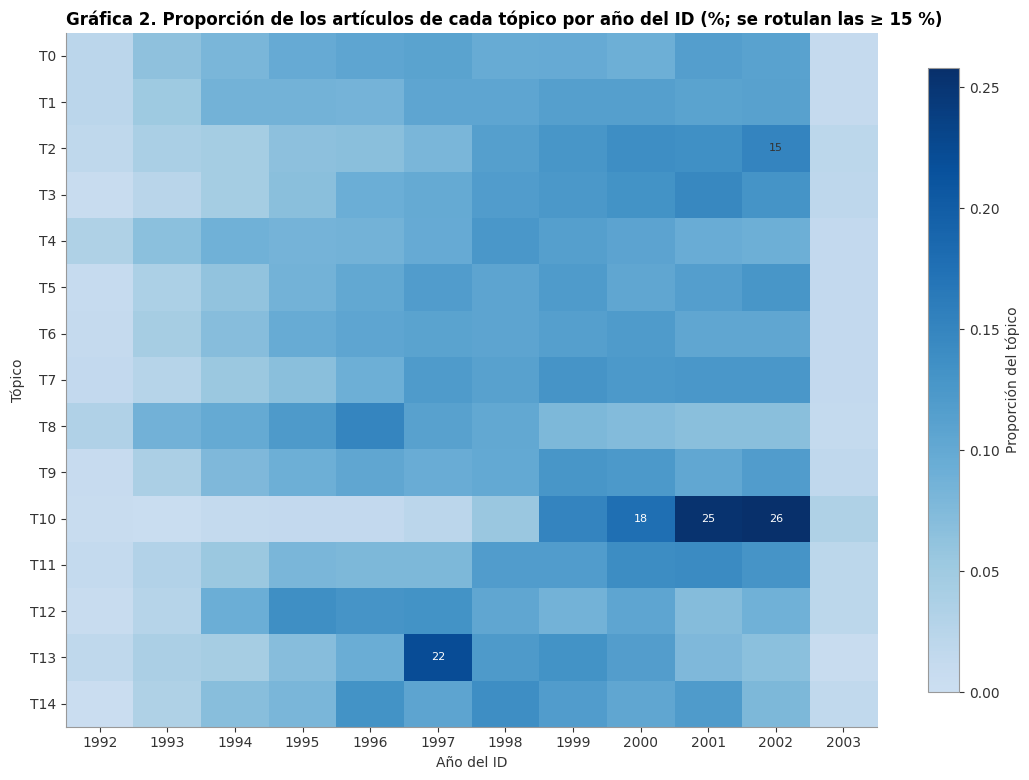

In [5]:
# Gráfica 2. Distribución por año de cada tópico (proporción de sus artículos en cada año)
anios = sorted(nodos["anio_id"].unique())
por_anio = (pd.crosstab(nodos.loc[nodos["topico"] >= 0, "topico"].map(nombre),
                        nodos.loc[nodos["topico"] >= 0, "anio_id"], normalize="index")
            .reindex(index=[nombre[c] for c in TOPICOS], columns=anios))

fig, ax = plt.subplots(figsize=(11, 0.42 * len(TOPICOS) + 1.6))
im = ax.imshow(por_anio.to_numpy(), cmap=CMAP_SEC, aspect="auto", vmin=0)
ax.set_xticks(range(len(anios)), labels=anios)
ax.set_yticks(range(len(TOPICOS)), labels=por_anio.index)
for i in range(por_anio.shape[0]):
    for j in range(por_anio.shape[1]):
        v = por_anio.iat[i, j]
        if v >= 0.15:
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.6 * np.nanmax(por_anio.to_numpy()) else TINTA)
estilo_ejes(ax, "Gráfica 2. Proporción de los artículos de cada tópico por año del ID (%; se rotulan las ≥ 15 %)",
            "Año del ID", "Tópico", rejilla=None)
fig.colorbar(im, ax=ax, label="Proporción del tópico", shrink=0.9)
plt.tight_layout()
plt.show()

In [6]:
# Dónde caen los artículos destacados del notebook 2 (top-100 de PageRank general y de autoridades de HITS)
pr_general = pagerank(G_sf)
_, autoridades = nx.hits(G_sf, max_iter=10_000, tol=1e-10)
autoridades = pd.Series(autoridades).sort_index()

def etiqueta_topico(indices):
    """
    Cuenta en qué tópico (o en las comunidades pequeñas) caen unos nodos.

    Parámetros
    ----------
    indices : pd.Index
        Índices de los nodos.

    Retorna
    -------
    pd.Series
        Conteo por tópico, con 'fuera de tópico' para las comunidades pequeñas.
    """
    return nodos.loc[indices, "topico"].map(lambda t: nombre.get(t, "fuera de tópico")).value_counts()


ubicacion = pd.DataFrame({"top-100 PageRank general": etiqueta_topico(pr_general.nlargest(100).index),
                          "top-100 autoridades HITS": etiqueta_topico(autoridades.nlargest(100).index)}).fillna(0).astype(int)
ubicacion = ubicacion.loc[ubicacion.sum(axis=1).sort_values(ascending=False).index]
display(ubicacion.T)

topico,T10,T0,T1,T5,T2,T7,T4,T3,T8,T11,T6,T12,T9,T14
top-100 PageRank general,5,20,15,11,9,8,8,6,5,4,3,3,2,1
top-100 autoridades HITS,83,13,3,0,0,1,0,0,0,0,0,0,0,0


**Observaciones: descripción de los tópicos**

- **Los tópicos son grupos cohesivos.** Entre el **68.2 %** (`T13`) y el **87.0 %** (`T4`) de las citas que hacen sus
  artículos se quedan dentro del tópico.
- **En su mayoría no son épocas (Gráfica 2).** Casi todos tienen un año mediano de 1998–1999 y abarcan de 1994 a 2002
  (p10–p90), así que agrupan artículos de todo el periodo. Las excepciones:
  - `T10` (año mediano **2001**, p10–p90 de **1998–2002**) concentra más del 15 % de sus artículos en cada año de 2000
    a 2002;
  - `T13` tiene el **22 %** de sus artículos en 1997;
  - `T8` es el más antiguo (año mediano **1997**, p10–p90 de **1993–2001**).
- **`T10` es la comunidad del efecto TKC.**
  - Contiene **83** de las top-100 autoridades de HITS.
  - Sus artículos más citados son `9803315` (**846**), `9804398` (**616**) y `9807344` (**503**), las autoridades
    principales del notebook 2.
  - Su año mediano tardío viene de los hubs de 2000–2002 que citan a esas autoridades de 1998.

  Louvain, un método distinto, confirma que la comunidad densa que encontró HITS existe.
- **El PageRank general está repartido.** Su top-100 se distribuye entre **14** de los 15 tópicos (de **20** en `T0` a
  **1** en `T14`; ninguno en `T13`) y ninguno cae fuera de tópico. Es otra muestra de que PageRank es global y HITS no.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. PageRank sensible a tópico</span></div>


Para cada tópico $T$ con conjunto de artículos $S$, el vector $v_S$ es el estacionario de

$$v' = \beta M v + (1 - \beta)\,\frac{e_S}{|S|},$$

donde $e_S$ vale 1 en los nodos de $S$ y 0 en los demás. La única diferencia con el PageRank general es **a dónde se
teletransporta** el lector: en lugar de saltar a cualquier artículo, salta a uno del tópico.

**En `networkx`.** Se pasa `personalization` $= \{i: 1/|S|\ \text{para}\ i \in S\}$. Con `dangling=None`, la
probabilidad que llega a un nodo colgante también se reparte según `personalization`, es decir, regresa a $S$. Así el
vector entero queda "anclado" al tópico. Es la opción elegida: en este grafo hay 2,460 nodos colgantes, entre ellos los
artículos viejos más citados, y si su masa se repartiera de forma uniforme cada tópico conservaría mucha menos masa
propia. El costo es que la mezcla de tópicos deja de ser exactamente lineal (sección 4). Se usa $\beta = 0.85$ sobre el grafo sin citas al futuro, igual que el PageRank
general del notebook 2.

**Cómo se lee.** $v_S$ es alto en los artículos de $S$ que son importantes **para el tópico** y en los artículos de fuera
a los que el tópico cita mucho, que son sus fundamentos. Los nodos que no están en ningún $S$ también reciben puntaje
por esta segunda vía.

In [7]:
# Un vector de PageRank por tópico (teletransportación uniforme a sus artículos)
tspr = {}
t0 = time.perf_counter()
for c in TOPICOS:
    S = nodos.index[nodos["comunidad"] == c]
    tspr[nombre[c]] = pagerank(G_sf, personalization={int(i): 1.0 / len(S) for i in S})
segundos_tspr = time.perf_counter() - t0
TSPR = pd.DataFrame(tspr)
print(f"{len(TOPICOS)} vectores en {segundos_tspr:.1f} s | todos suman 1: {np.allclose(TSPR.sum(), 1)}")

masa = pd.DataFrame({
    "masa dentro de S": [TSPR.loc[nodos["comunidad"] == c, nombre[c]].sum() for c in TOPICOS],
    "masa en otros tópicos": [TSPR.loc[(nodos["topico"] >= 0) & (nodos["comunidad"] != c), nombre[c]].sum() for c in TOPICOS],
    "masa en nodos fuera de tópico": [TSPR.loc[nodos["topico"] == -1, nombre[c]].sum() for c in TOPICOS],
    "% del top-100 dentro de S": [(nodos.loc[TSPR[nombre[c]].nlargest(100).index, "comunidad"] == c).mean() for c in TOPICOS],
}, index=[nombre[c] for c in TOPICOS])
display(masa.map(lambda v: pct(v, 1)))

fuera = nodos["topico"] == -1
mejor_lugar_fuera = TSPR.rank(ascending=False).loc[fuera].min()
positivo = TSPR.loc[fuera] > 0
print(f"Nodos fuera de tópico: {fuera.sum():,} | con puntaje > 0 en todos los vectores: {positivo.all(axis=1).sum():,} | "
      f"en al menos uno: {positivo.any(axis=1).sum():,} | en ninguno: {(~positivo.any(axis=1)).sum():,} | "
      f"masa en el PageRank general: {pct(pr_general[fuera].sum())}")
print(f"Mejor lugar de un nodo fuera de tópico en algún vector: {int(mejor_lugar_fuera.min())} "
      f"(en {mejor_lugar_fuera.idxmin()})")

15 vectores en 12.5 s | todos suman 1: True


,masa dentro de S,masa en otros tópicos,masa en nodos fuera de tópico,% del top-100 dentro de S
T0,83.4 %,16.6 %,0.0 %,92.0 %
T1,85.8 %,14.2 %,0.1 %,90.0 %
T2,83.9 %,15.7 %,0.3 %,89.0 %
T3,82.4 %,17.6 %,0.0 %,89.0 %
T4,87.4 %,12.5 %,0.1 %,95.0 %
T5,80.3 %,19.7 %,0.0 %,85.0 %
T6,81.8 %,18.2 %,0.0 %,89.0 %
T7,74.0 %,25.9 %,0.1 %,78.0 %
T8,74.4 %,25.6 %,0.0 %,81.0 %
T9,73.6 %,26.3 %,0.0 %,76.0 %


Nodos fuera de tópico: 526 | con puntaje > 0 en todos los vectores: 110 | en al menos uno: 163 | en ninguno: 363 | masa en el PageRank general: 1.03 %
Mejor lugar de un nodo fuera de tópico en algún vector: 237 (en T2)


<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.1 Comparación entre tópicos y con el PageRank general</span></div>


Con varios tópicos, una tabla de top-k por tópico sería ilegible. La comparación se hace con un **mapa de calor del
Jaccard del top-100** entre cada par de vectores, incluido el PageRank general. El detalle de los top-k queda para
cuatro tópicos representativos (sección 3.2).

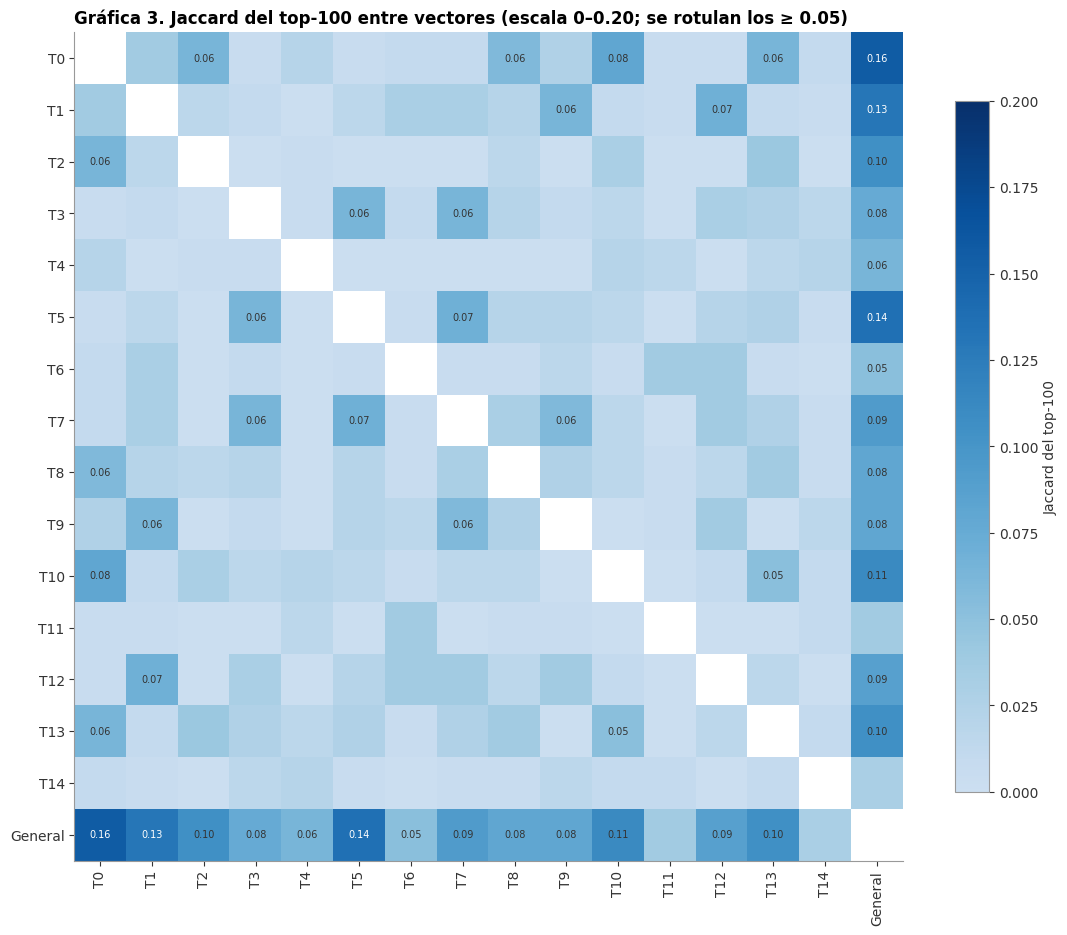

Jaccard top-100 con el PageRank general: mediana 0.087, máximo 0.156 (T0), mínimo 0.031 (T14)
Jaccard top-100 entre tópicos: mediana 0.010, máximo 0.081 (T0 y T10); pares con Jaccard = 0: 25 de 105


Spearman ρ de cada tópico con el PageRank general: de 0.618 (T0) a 0.771 (T14)


In [8]:
# Gráfica 3. Jaccard del top-100 entre los vectores de tópico y el PageRank general
vectores = pd.concat([TSPR, pr_general.rename("General")], axis=1)
etiquetas = list(vectores.columns)
J = pd.DataFrame([[jaccard_top(vectores[a], vectores[b], 100) for b in etiquetas] for a in etiquetas],
                 index=etiquetas, columns=etiquetas)

fig, ax = plt.subplots(figsize=(0.55 * len(etiquetas) + 2.5, 0.5 * len(etiquetas) + 1.5))
mascara = np.eye(len(etiquetas), dtype=bool)
vmax = np.ceil(J.where(~mascara).max().max() * 20) / 20   # máximo fuera de la diagonal, redondeado a 0.05
im = ax.imshow(np.where(mascara, np.nan, J.to_numpy()), cmap=CMAP_SEC, vmin=0, vmax=vmax)
ax.set_xticks(range(len(etiquetas)), labels=etiquetas, rotation=90)
ax.set_yticks(range(len(etiquetas)), labels=etiquetas)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if i != j and J.iat[i, j] >= 0.05:
            ax.text(j, i, f"{J.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if J.iat[i, j] > 0.6 * vmax else TINTA)
estilo_ejes(ax, f"Gráfica 3. Jaccard del top-100 entre vectores (escala 0–{vmax:.2f}; se rotulan los ≥ 0.05)",
            None, None, rejilla=None)
fig.colorbar(im, ax=ax, label="Jaccard del top-100", shrink=0.8)
plt.tight_layout()
plt.show()

fuera_diag = J.where(~mascara)
print(f"Jaccard top-100 con el PageRank general: mediana {fuera_diag.loc['General', TSPR.columns].median():.3f}, "
      f"máximo {fuera_diag.loc['General', TSPR.columns].max():.3f} ({fuera_diag.loc['General', TSPR.columns].idxmax()}), "
      f"mínimo {fuera_diag.loc['General', TSPR.columns].min():.3f} ({fuera_diag.loc['General', TSPR.columns].idxmin()})")
entre = fuera_diag.loc[TSPR.columns, TSPR.columns].stack()
print(f"Jaccard top-100 entre tópicos: mediana {entre.median():.3f}, máximo {entre.max():.3f} "
      f"({entre.idxmax()[0]} y {entre.idxmax()[1]}); pares con Jaccard = 0: {(entre == 0).sum() // 2} "
      f"de {len(entre) // 2}")
rho = pd.Series({t: spearmanr(TSPR[t], pr_general).statistic for t in TSPR.columns})
print(f"Spearman ρ de cada tópico con el PageRank general: de {rho.min():.3f} ({rho.idxmin()}) "
      f"a {rho.max():.3f} ({rho.idxmax()})")

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3.2 Cuatro tópicos representativos</span></div>


Se eligen con criterios objetivos, para no escoger a mano los que "se ven bien":

- el **más grande**;
- el que contiene más **autoridades de HITS** (la comunidad densa del efecto TKC);
- el de **año mediano más antiguo**;
- el de **año mediano más reciente**.

Si un tópico cumple dos criterios, se toma el siguiente en la lista del segundo criterio. Para cada uno se muestran sus
10 artículos principales, su lugar en el PageRank general y si pertenecen al tópico.

In [9]:
# Selección de los tópicos representativos y sus top-10
anio_mediano = descripcion["año mediano"]
con_autoridades = ubicacion["top-100 autoridades HITS"].drop("fuera de tópico", errors="ignore").sort_values(ascending=False)
candidatos = [("más grande", [nombre[TOPICOS[0]]]),
              ("más autoridades de HITS", list(con_autoridades.index)),
              ("más antiguo", list(anio_mediano.sort_values(kind="stable").index)),
              ("más reciente", list(anio_mediano.sort_values(ascending=False, kind="stable").index))]
representativos = {}
for criterio, lista in candidatos:
    elegido = next(t for t in lista if t not in representativos)
    representativos[elegido] = criterio
print("Tópicos representativos:", {t: c for t, c in representativos.items()})

lugar_general = pr_general.rank(ascending=False, method="min").astype(int)
for t, criterio in representativos.items():
    c = int(t[1:])
    v = TSPR[t]
    top = v.nlargest(10).index
    tabla = pd.DataFrame({"id": nodos.loc[top, "id"].to_numpy(), "año": nodos.loc[top, "anio_id"].to_numpy(),
                          "k_in": nodos.loc[top, "k_in"].to_numpy(),
                          "en el tópico": np.where(nodos.loc[top, "comunidad"] == c, "sí", "no"),
                          f"PageRank {t}": v.loc[top].round(5).to_numpy(),
                          "lugar general": lugar_general.loc[top].to_numpy()},
                         index=pd.RangeIndex(1, 11, name="lugar"))
    print(f"{t} ({criterio}): {descripcion.loc[t, 'nodos']:,} nodos, año mediano {descripcion.loc[t, 'año mediano']}, "
          f"Jaccard top-100 con el general {J.loc[t, 'General']:.3f}")
    display(tabla)

Tópicos representativos: {'T0': 'más grande', 'T10': 'más autoridades de HITS', 'T8': 'más antiguo', 'T2': 'más reciente'}
T0 (más grande): 4,295 nodos, año mediano 1998, Jaccard top-100 con el general 0.156


,id,año,k_in,en el tópico,PageRank T0,lugar general
lugar,,,,,,
1,9206203,1992,32,sí,0.01164,3
2,9303230,1993,347,sí,0.00703,8
3,9205227,1992,20,sí,0.00643,11
4,9211266,1992,68,sí,0.00564,15
5,9207219,1992,30,sí,0.00538,46
6,9307201,1993,166,sí,0.00506,61
7,9207234,1992,232,sí,0.00488,42
8,9210235,1992,279,sí,0.00458,40
9,9203220,1992,63,sí,0.00455,24


T10 (más autoridades de HITS): 1,499 nodos, año mediano 2001, Jaccard top-100 con el general 0.111


,id,año,k_in,en el tópico,PageRank T10,lugar general
lugar,,,,,,
1,9803315,1998,846,sí,0.03215,6
2,9211309,1992,122,sí,0.02069,18
3,9804398,1998,616,sí,0.01985,27
4,9803466,1998,305,sí,0.01434,59
5,9807344,1998,503,sí,0.01240,78
6,9403290,1994,163,sí,0.00980,115
7,9806292,1998,289,sí,0.00866,137
8,9905221,1999,448,sí,0.00862,152
9,9805217,1998,100,sí,0.00714,196


T8 (más antiguo): 2,108 nodos, año mediano 1997, Jaccard top-100 con el general 0.081


,id,año,k_in,en el tópico,PageRank T8,lugar general
lugar,,,,,,
1,9206242,1992,140,sí,0.00978,5
2,9204214,1992,98,sí,0.00836,81
3,9204204,1992,59,sí,0.00742,113
4,9303255,1993,154,sí,0.00741,1
5,9206205,1992,97,sí,0.00597,17
6,9207278,1992,68,sí,0.00478,157
7,9411426,1994,248,sí,0.00444,277
8,9207226,1992,20,sí,0.00400,310
9,9312324,1993,100,sí,0.00359,358


T2 (más reciente): 3,559 nodos, año mediano 1999, Jaccard top-100 con el general 0.105


,id,año,k_in,en el tópico,PageRank T2,lugar general
lugar,,,,,,
1,9207213,1992,69,sí,0.01094,13
2,9206242,1992,140,no,0.00980,5
3,9203213,1992,6,sí,0.00758,41
4,9306212,1993,78,sí,0.00735,47
5,9212204,1992,34,sí,0.00697,55
6,9311214,1993,141,sí,0.00641,58
7,9807216,1998,399,sí,0.00526,87
8,9311306,1993,64,sí,0.00491,107
9,9505425,1995,158,sí,0.00467,116


In [10]:
# Artículos que más suben al pasar del PageRank general al de su propio tópico (dentro del top-100 del tópico)
filas_suben = []
for t in representativos:
    c = int(t[1:])
    lugar_t = TSPR[t].rank(ascending=False, method="min").astype(int)
    top = TSPR[t].nlargest(100).index
    propios = [i for i in top if nodos.loc[i, "comunidad"] == c]
    mejor = max(propios, key=lambda i: lugar_general[i] - lugar_t[i])
    filas_suben.append({"tópico": t, "id": nodos.loc[mejor, "id"], "año": nodos.loc[mejor, "anio_id"],
                        "k_in": nodos.loc[mejor, "k_in"], "lugar en el tópico": lugar_t[mejor],
                        "lugar general": lugar_general[mejor]})
display(pd.DataFrame(filas_suben).set_index("tópico"))

,id,año,k_in,lugar en el tópico,lugar general
tópico,,,,,
T0,9302317,1993,59,100,776
T10,9906542,1999,21,100,2707
T8,9212284,1992,59,95,2532
T2,9605413,1996,47,97,948


**Observaciones: PageRank sensible a tópico**

- **Cada vector queda anclado a su tópico.** Los **15** vectores se calculan en segundos y todos suman 1.
  - Entre el **66.9 %** (`T13`) y el **87.4 %** (`T4`) de la masa de cada vector queda en su propio tópico.
  - Entre el **76 %** (`T9`) y el **95 %** (`T4`) del top-100 de cada vector son artículos del tópico.
  - El resto de la masa va a **otros tópicos**: son los fundamentos que el tópico cita.
- **Los nodos fuera de tópico.** De los **526**, **110** tienen puntaje positivo en los 15 vectores, **163** en al menos
  uno y **363** en ninguno: no se llega a ellos siguiendo citas desde ningún $S$, porque solo los citan artículos de su
  propia comunidad pequeña. En el PageRank general, que se teletransporta a todos, reciben el **1.03 %** de la masa. El
  mejor lugar de uno de ellos en algún vector es el **237** (en `T2`).
- **Cada tópico tiene su propio top (Gráfica 3).** Entre tópicos, el Jaccard del top-100 tiene una mediana de **0.010**
  y un máximo de **0.081** (`T0` y `T10`); **25** de los **105** pares no comparten ningún artículo. Contra el PageRank
  general, la mediana es **0.087**, con un rango de **0.031** (`T14`) a **0.156** (`T0`). El ranking completo de cada
  tópico se parece moderadamente al general: Spearman de **0.618** (`T0`) a **0.771** (`T14`).
- **Tópicos representativos.**
  - `T0`: el más grande.
  - `T10`: el de las autoridades de HITS.
  - `T8`: el más antiguo.
  - `T2`: el más reciente después de `T10`, que ya estaba elegido; empata en año mediano 1999 con `T3`, `T7` y `T11`
    y se toma el más grande.
- **Sus top-10.**
  - Casi todos son artículos **del propio tópico**. La excepción es `9206242`, de `T8`, que es 2.º en `T2`: un
    fundamento que `T2` cita mucho.
  - **El sesgo por antigüedad sigue dentro de cada tópico.** En `T0`, **8** de los 10 son de 1992 y **2** de 1993; en
    `T8`, **7** de 1992. `T10` es el único con mayoría reciente: **6** de 1998.
  - Aparecen artículos poco visibles en el ranking general. En `T2`, `9203213` es 3.º con solo **6** citas (lugar
    general **41**). En `T10`, `9710204` es 10.º (general **218**). En `T8`, `9207226` es 8.º con **20** citas
    (general **310**).
  - En el top-100 de cada tópico hay artículos que suben mucho respecto al ranking general: `9906542` (`T10`) pasa del
    lugar general **2,707** al **100** del tópico, y `9212284` (`T8`), del **2,532** al **95**.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · TSPR</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Consulta de usuario como mezcla de tópicos</span></div>


Un usuario interesado en varios temas se representa con pesos $w_T \ge 0$, $\sum_T w_T = 1$. Como la ecuación de
PageRank es **lineal en el vector de teletransportación**, el vector de la mezcla es la misma mezcla de los vectores
precalculados:

$$v_{\text{usuario}} = \sum_T w_T\, v_{S_T}.$$

No hace falta recalcular PageRank para cada usuario: basta con una combinación lineal de los vectores guardados. Es la
idea práctica de Haveliwala.

**Matiz: la linealidad depende de los nodos colgantes.** La igualdad es exacta si la masa de los colgantes se reparte
con un vector **fijo**, el mismo para todos los tópicos. Aquí se reparte según la personalización $p$ (sección 3), así
que el vector estacionario es

$$v = (1-\beta)\,\big(I - \beta M - \beta\, p\, d^\top\big)^{-1} p,$$

con $d$ el indicador de los colgantes: $p$ aparece **dentro** de la matriz y la mezcla de vectores es solo una
**aproximación**. Se mide el error comparando la mezcla con un PageRank calculado directamente con `personalization`
$= \sum_T w_T\, e_{S_T}/|S_T|$, que es la respuesta exacta y cuesta alrededor de un segundo.

**Ejemplo.** Un usuario con interés de 70 % en el tópico más grande y 30 % en el tópico de las autoridades de HITS
(los dos primeros representativos).

In [11]:
# Mezcla de tópicos: combinación lineal de vectores precalculados y comprobación contra el cálculo directo
t_a, t_b = list(representativos)[:2]
pesos = {t_a: 0.7, t_b: 0.3}
v_mezcla = sum(w * TSPR[t] for t, w in pesos.items())

personalizacion = {}
for t, w in pesos.items():
    S = nodos.index[nodos["comunidad"] == int(t[1:])]
    for i in S:
        personalizacion[int(i)] = personalizacion.get(int(i), 0.0) + w / len(S)
v_directo = pagerank(G_sf, personalization=personalizacion)
calidad_mezcla = pd.Series({
    "‖mezcla − directo‖₁": f"{np.abs(v_mezcla - v_directo).sum():.2e}",
    "Error relativo máximo de un puntaje (top-100 directo)":
        pct((np.abs(v_mezcla - v_directo) / v_directo).loc[v_directo.nlargest(100).index].max(), 1),
    "Jaccard top-20 (mezcla vs directo)": f"{jaccard_top(v_mezcla, v_directo, 20):.3f}",
    "Jaccard top-100 (mezcla vs directo)": f"{jaccard_top(v_mezcla, v_directo, 100):.3f}",
    "Spearman ρ (todos los nodos)": f"{spearmanr(v_mezcla, v_directo).statistic:.4f}",
}, name="Valor").rename_axis(f"Usuario {pesos}").to_frame()
display(calidad_mezcla)

lugar = {nombre_v: v.rank(ascending=False, method="min").astype(int)
         for nombre_v, v in [("mezcla", v_mezcla), (t_a, TSPR[t_a]), (t_b, TSPR[t_b]), ("general", pr_general)]}
top = v_directo.nlargest(10).index
display(pd.DataFrame({"id": nodos.loc[top, "id"].to_numpy(), "año": nodos.loc[top, "anio_id"].to_numpy(),
                      "tópico": nodos.loc[top, "topico"].map(lambda c: nombre.get(c, "fuera")).to_numpy(),
                      **{f"lugar {k}": v.loc[top].to_numpy() for k, v in lugar.items()}},
                     index=pd.RangeIndex(1, 11, name="lugar (cálculo directo)")))
print(f"Jaccard top-100 del usuario (directo) con {t_a}: {jaccard_top(v_directo, TSPR[t_a], 100):.3f} | con {t_b}: "
      f"{jaccard_top(v_directo, TSPR[t_b], 100):.3f} | con el general: {jaccard_top(v_directo, pr_general, 100):.3f}")

,Valor
"Usuario {'T0': 0.7, 'T10': 0.3}",
‖mezcla − directo‖₁,4.50e-02
Error relativo máximo de un puntaje (top-100 directo),8.2 %
Jaccard top-20 (mezcla vs directo),1.000
Jaccard top-100 (mezcla vs directo),0.923
Spearman ρ (todos los nodos),0.9999


,id,año,tópico,lugar mezcla,lugar T0,lugar T10,lugar general
lugar (cálculo directo),,,,,,,
1,9803315,1998,T10,1,247,1,6
2,9206203,1992,T0,2,1,23,3
3,9211309,1992,T10,3,224,2,18
4,9804398,1998,T10,4,556,3,27
5,9303230,1993,T0,5,2,18,8
6,9205227,1992,T0,6,3,19,11
7,9803466,1998,T10,7,657,4,59
8,9211266,1992,T0,8,4,54,15
9,9807344,1998,T10,10,936,5,78


Jaccard top-100 del usuario (directo) con T0: 0.613 | con T10: 0.242 | con el general: 0.190


**Observaciones: consulta de usuario**

- **La mezcla lineal es una buena aproximación en el top.** Para el usuario {`T0`: 0.7, `T10`: 0.3}, la diferencia
  con el cálculo directo es $\lVert\cdot\rVert_1$ = **4.50e-02**, con un error relativo máximo de **8.2 %** en un
  puntaje del top-100. Los rankings casi coinciden: Jaccard de **1.000** en el top-20, de **0.923** en el top-100 y
  Spearman **0.9999**. El error lo causa el tratamiento de los colgantes (fórmula de arriba). Si hace falta el valor
  exacto, un PageRank directo cuesta alrededor de un segundo.
- **El top del usuario mezcla los dos tópicos, pero no en proporción a los pesos.** De los 10 primeros, **5** son de
  `T10` (encabezados por `9803315`) y **5** de `T0` (`9206203`, `9303230`…), aunque `T10` pesa solo 30 %. La razón es
  que el vector de `T10` está más concentrado: su máximo es **0.03215**, contra **0.01164** del de `T0`. Sus artículos
  principales sobreviven al multiplicarlos por 0.3. Un peso no es una "cuota" del top-k.
- **El resultado es una vista nueva.** El top-100 del usuario comparte **0.613** (Jaccard) con `T0`, **0.242** con
  `T10` y solo **0.190** con el PageRank general.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Conclusiones y limitaciones</span></div>


Las conclusiones reúnen los tres notebooks: calidad y preprocesamiento (N1), representación, PageRank y HITS (N2), y
PageRank sensible a tópico (N3). Las cifras son las de sus salidas.

### Conclusiones

1. **La calidad de las llaves decidía todo lo demás (N1).**
   - Los IDs de las aristas habían perdido los ceros a la izquierda (el **52.21 %** de los orígenes).
   - El archivo de fechas mezclaba **6,683** filas *cross-listed*, **1,077** de ellas disfrazadas de IDs normales de
     7 dígitos. Se detectaron comparando el `AAMM` del ID con la fecha.
   - Al separarlas, las **31,874** fechas propias no tienen ningún ID repetido y cubren el **88.46 %** de los nodos. La
     falta de fechas es un corte en el tiempo (**12/03/2002**), no un problema aleatorio.
2. **Las citas al futuro son pocas, pero cambian la estructura del grafo (N1, N2).**
   - Son **1,852** aristas (**0.44 %**) y crean la SCC de **12,711** nodos que reporta SNAP; sin ellas, la SCC mayor
     tiene **4** nodos.
   - En PageRank colocan en el top-100 a **5** artículos que, sin ellas, quedan fuera del top-1,000 (`9908362` pasa del
     lugar **11** al **7,803**).
   - Por eso el análisis principal usa el grafo **sin citas al futuro**, y el grafo completo queda como robustez.
3. **La representación dispersa y la teletransportación son necesarias, no opcionales (N2).**
   - La matriz CSR ocupa **5.2 MB**, contra **9.55 GB** densa.
   - Con **2,393** nodos colgantes, el paseo sin impuestos conserva solo **0.0075** de su probabilidad después de
     10 pasos.
   - Eliminar los colgantes de forma recursiva quitaría el **27.95 %** del grafo, incluidos los artículos más viejos
     y más citados.
4. **PageRank no es contar citas (N2).**
   - La correlación de rangos con $k_{in}$ es alta ($\rho$ = **0.9104**), pero el top-20 comparte apenas el **0.081**
     (Jaccard) con el de citas: una cita vale lo que vale quien cita, dividido entre sus referencias.
   - El ranking completo es estable frente a $\beta$ ($\rho \ge$ **0.9987**). El top-20 se mueve más (Jaccard **0.667**
     entre $\beta$ = 0.70 y 0.95), así que se usó el estándar $\beta$ = 0.85.
5. **El sesgo por antigüedad es el efecto más fuerte del ranking (N1, N2).**
   - Como las citas apuntan al pasado y los artículos recientes tuvieron poco tiempo para ser citados, el top-100 de
     PageRank tiene **47** artículos de 1992 y **ninguno** de 1999 en adelante ($\rho$ con el año = **−0.4729**).
   - El PageRank relativo a la mediana de cada cohorte reparte mejor los años (1998 pasa de **6** a **16** artículos en
     el top-100), pero no corrige la censura de 2000–2002.
6. **HITS mide otra noción de importancia y es sensible a una comunidad densa (N2, N3).**
   - Sus autoridades casi no coinciden con PageRank: Jaccard del top-100 de **0.053**.
   - Las autoridades son artículos de **1998–1999** y los hubs, de **1999–2002**. El bloque que forman tiene una
     densidad **773 veces** la del grafo: es el efecto TKC, favorecido por una brecha espectral pequeña
     ($\sigma_1/\sigma_2$ = **1.0762**).
   - La comunidad de Louvain `T10` contiene **83** de las top-100 autoridades, lo que confirma con otro método que esa
     comunidad existe.
7. **El grafo tiene tópicos bien definidos sin necesidad de texto (N3).**
   - Louvain encuentra **103** comunidades ($Q$ = **0.7281**). Las **15** que superan el 1 % cubren el **98.48 %** de
     los nodos y retienen entre el **68.2 %** y el **87.0 %** de sus citas.
   - En su mayoría abarcan todo el periodo, así que agrupan temas y no épocas.
8. **El PageRank sensible a tópico produce rankings realmente distintos (N3).**
   - El Jaccard mediano del top-100 entre tópicos es **0.010**, y contra el PageRank general, **0.087**.
   - Aparecen artículos que el ranking general no ve; por ejemplo, `9203213` es 3.º en `T2` con **6** citas.
   - Una consulta como mezcla de tópicos se aproxima muy bien con la combinación lineal de los vectores precalculados
     (el mismo top-20; Jaccard del top-100 de **0.923**). No es exacta porque la masa de los colgantes vuelve a cada
     $S$.

### Limitaciones

- **Citas fuera del conjunto.** El grafo solo tiene citas entre artículos de `hep-ph` en arXiv. Las referencias a
  trabajos anteriores a 1992 o de otras categorías no están: los artículos de 1992 citan en promedio **0.3** artículos
  del conjunto. Los artículos viejos quedan como nodos colgantes con mucho puntaje.
- **Censura temporal.** Las fechas terminan en marzo de 2002 y las citas, a principios de 2003. Los artículos de
  2002–2003 tienen solo `mes_id` (con error de a lo más un mes en el **99.76 %** de los casos comprobables) y muy pocas
  citas. Ningún ajuste sobre estos datos corrige esa falta de tiempo.
- **Definición de tópico.**
  - Los tópicos son comunidades de Louvain de **una sola corrida** (`seed=42`, `resolution=1`): otra semilla u otra
    resolución darían otra partición.
  - No tienen nombre, porque no se usó texto.
  - El umbral del 1 % deja **526** nodos fuera de todo conjunto $S$; **363** de ellos no reciben puntaje en ningún
    vector de tópico.
- **Citas al futuro.** Se excluyeron del análisis principal. Su origen (versiones revisadas o un error en la
  extracción de referencias) es una **hipótesis**: los IDs de los citantes no tienen el patrón de colisión, pero
  confirmarlo requeriría los metadatos de las versiones en arXiv.
- **Sensibilidad a parámetros.** El top-k de PageRank depende de $\beta$, y el de HITS de un vector principal poco
  separado del segundo. También dependen de los umbrales de los tópicos y de la tolerancia (`tol=1e-10`).
- **Decisiones de limpieza.**
  - Se eliminaron **44** autocitas y se separaron los *cross-listed*; con eso, **3** nodos se quedaron sin fecha.
  - La tolerancia de un mes en la coherencia del ID es un criterio razonable, pero no es la única opción.
  - El diámetro se estimó con una muestra de BFS (cota inferior de **11**, contra el **12** de SNAP).